# 03 · Extreme Value Theory calibration
Peaks-over-threshold: τ₀ = 90th percentile of held-out D²_M, Weibull fitted to the exceedances, S(q) = exp(−((D²−τ₀)/λ)^κ).

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

In [2]:
from src.evt import WeibullTail
from src.mfa import MFA
for s in ['passage']:
    e = WeibullTail.load(f'results/models/evt_{s}.json')
    print(s, e, ' threshold D* at alpha=0.01:', round(e.threshold(0.01), 1))

passage WeibullTail(tau0=483.096190783861, kappa=1.0528628834162568, lam=50.854198312049434, tail_percentile=90.0, n_exceed=1059, ks_stat=0.023946904834629912, ks_pvalue=0.5698083166404753)  threshold D* at alpha=0.01: 700.0


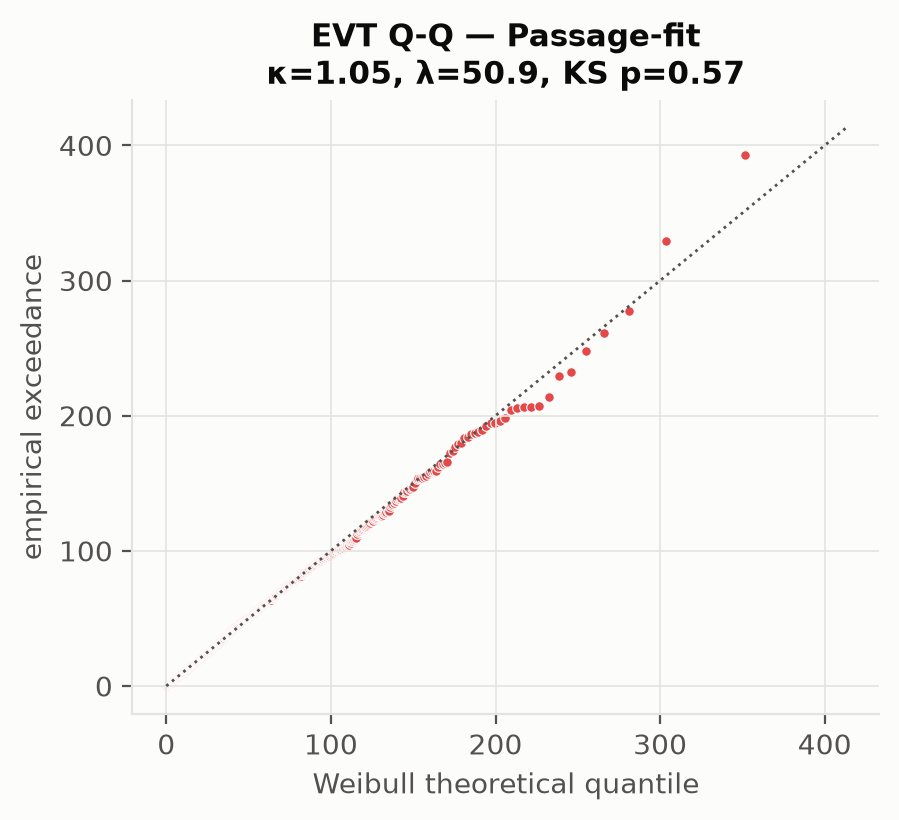

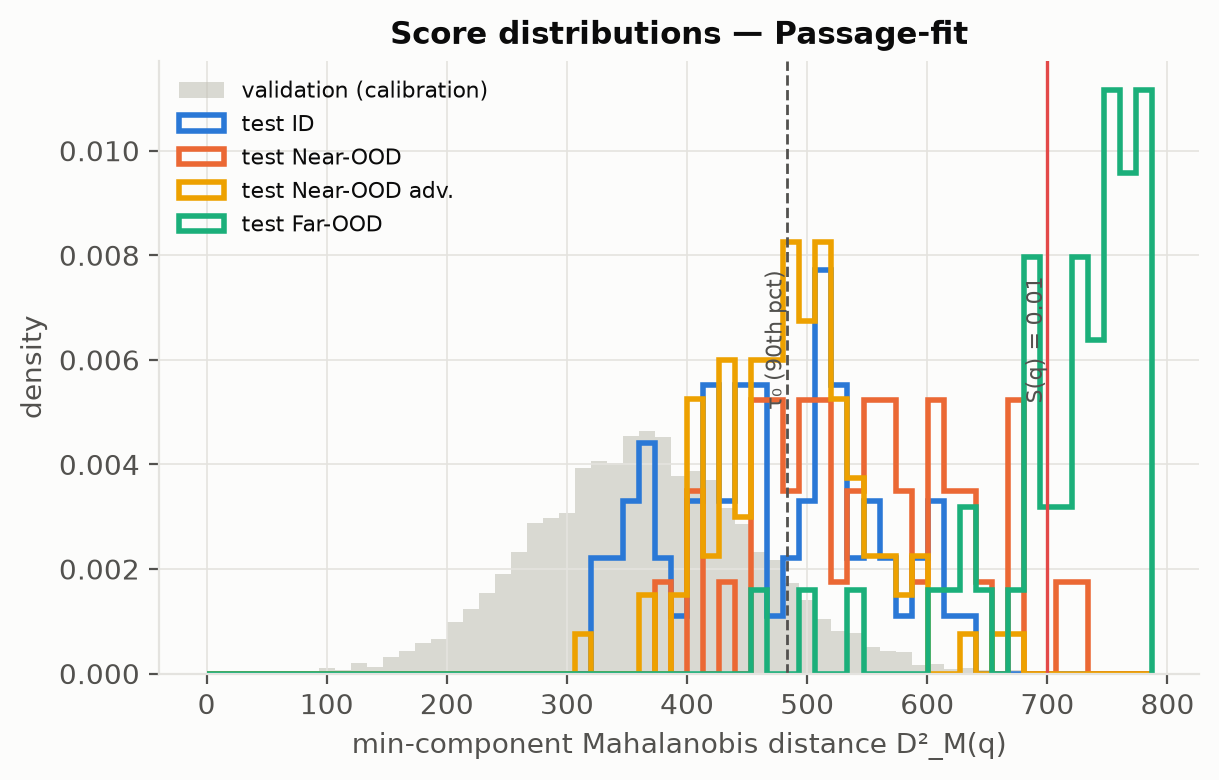

In [3]:
display(Image('results/evt_qq.png'))
display(Image('results/score_dist.png'))

## Sensitivity to α

In [4]:
op = pd.read_csv('results/operating_points.csv')
op[op.method.str.contains('EVT')].round(3)

,source,method,rule,ID pass rate,Near-OOD reject rate,Near-OOD adv. reject rate,Far-OOD reject rate
7,passage,MFA + EVT (proposed),S(q) < 0.5,0.706,0.581,0.27,0.98
8,passage,MFA + EVT (proposed),S(q) < 0.2,0.853,0.419,0.10,0.97
9,passage,MFA + EVT (proposed),S(q) < 0.1,0.926,0.326,0.05,0.97
10,passage,MFA + EVT (proposed),S(q) < 0.05,0.985,0.186,0.03,0.95
11,passage,MFA + EVT (proposed),S(q) < 0.01,1.000,0.047,0.00,0.84
12,passage,MFA + EVT (proposed),S(q) < 0.001,1.000,0.000,0.00,0.46
13,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.5 (3-fold CV),0.735,0.535,0.19,0.97
14,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.2 (3-fold CV),0.868,0.349,0.07,0.97
15,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.1 (3-fold CV),0.926,0.302,0.04,0.97
16,passage,MFA + EVT (proposed) · ID-question calibrated,S(q) < 0.05 (3-fold CV),0.985,0.209,0.03,0.96
